# 04 — A model built for numbers: TimesFM 2.5

The language models in notebooks 02 and 03 read prices as text. **TimesFM 2.5** (Google Research, 200 million parameters, Apache-2.0 licence) was trained on numbers: give it a series and it forecasts the next values, with a range around them. It does not trade and does not read instructions, so it plays the game through **one fixed rule**:

1. Each day, at the close, TimesFM forecasts tomorrow's close from a stretch of history.
2. **Long** if its median forecast is more than 0.04% above today's close; **short** if more than 0.04% below; **flat** in between. 0.04% is the cost of a round trip (two fills at 0.02%): a smaller expected move cannot pay for the trade.
3. Same game as everyone else: fill at the next open, the same disaster stop (three ATRs from entry, at most 15%), the same 0.02% per fill.
4. Its daily chance of a rise (`p_up`) is read off its own forecast range.

**Two settings matter, and they are chosen on a different year.** What TimesFM is shown, **prices or daily returns**, and **how much history**. The first run used Google's example settings (prices, 1,024 days, about four years) and lost heavily: TimesFM kept forecasting a return to oil's four-year average while oil rallied (section 6). So, before running the test year again, section 3 tries **12 versions** (prices or returns, 3 months to 10 years of history) on the **previous year, October 2024 to September 2025**, and picks one by a rule fixed in advance, on forecast quality only, never on P&L.

**Why the test year is clean for TimesFM.** The model card lists its training data: the GIFT-Eval pretraining set, Wikipedia pageviews up to November 2023, Google Trends up to the end of 2022, and synthetic series. Version 2.5 was published in September 2025, before the test year (1 October 2025 to 30 September 2026). It sees only a column of numbers, with no dates or names. The development year (October 2024 to September 2025) is also after the listed training data.

The weights download from Hugging Face the first time (about 1 GB) and are never stored in this project. TimesFM is not an official Google product, and this project is not endorsed by Google.

Expect about 5 to 15 minutes for section 3 (3,000 forecasts) and a few minutes for the year. For a quick look at the year, set `N_DAYS = 10`.

In [20]:
import sys, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from oilbench import rules
from oilbench.data import Market, load_or_download
from oilbench.agents import Flat, BuyAndHold, TimesFMAgent, load_timesfm, timesfm_version, tfm_series, tfm_view
from oilbench.replay import run, decision_dates, season_span, end_after, collect_saved
from oilbench.metrics import random_traders_cached, forecast_scores, pnl_metrics, trade_metrics, beats
from oilbench.live import LiveView
from oilbench.report import export_summary, load_summary, pnl_chart, luck_chart, trades_chart, calibration_chart, scoreboard, LABELS
from oilbench import tfm_select as sel

N_DAYS = None                     # None = the full year; 10 = a quick look
CHECKPOINT = "google/timesfm-2.5-200m-pytorch"
REVISION = None                   # None = latest; set a Hugging Face commit hash to pin the exact weights
QUICK = "" if N_DAYS is None else "_quick"                # a quick look never overwrites the full year
RESULTS = ROOT / "data" / f"results{QUICK}"
SUMMARY_FOLDER = f"summary{QUICK}"
SELECTION_FILE = ROOT / "data" / "results" / "timesfm_selection_dev_year.csv"

# 10 years of history before October 2024 needs prices from about 2014: download further back if needed
raw = load_or_download(ROOT / "data" / "wti_daily.csv")
if raw.index[0] > pd.Timestamp("2014-06-01"):
    raw = load_or_download(ROOT / "data" / "wti_daily.csv", refresh=True, start="2010-01-01")
md_ = Market.from_raw(raw, adjust_rolls=rules.ADJUST_ROLLS)
END = rules.WINDOW_END if N_DAYS is None else end_after(md_, N_DAYS)
span = season_span(md_, rules.WINDOW_START, END)
dds = decision_dates(md_, rules.WINDOW_START, END)
print(f"Prices from {raw.index[0].date()} to {raw.index[-1].date()}")
print(f"{'QUICK LOOK: ' if QUICK else ''}Test year: {span['days']} decisions; first trade at the open of {span['first_fill']}, "
      f"last mark at the close of {span['last_mark']}; results go to {RESULTS.relative_to(ROOT)}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

Prices from 2010-01-04 to 2026-10-19
Test year: 250 decisions; first trade at the open of 2025-10-02, last mark at the close of 2026-09-30; results go to data/results


## 1. Load TimesFM 2.5

In [21]:
t0 = time.time()
forecaster = load_timesfm(CHECKPOINT, revision=REVISION, max_context=2560)   # up to 10 years of history
print(f"TimesFM package {timesfm_version()}, checkpoint {CHECKPOINT}, loaded in {time.time() - t0:.0f}s")
try:                                   # record exactly which weights were used
    from huggingface_hub import HfApi
    WEIGHTS = REVISION or HfApi().model_info(CHECKPOINT).sha
except Exception as e:
    WEIGHTS = f"unknown ({type(e).__name__})"
print("Hugging Face commit of the weights:", WEIGHTS)

TimesFM package 3.0.2, checkpoint google/timesfm-2.5-200m-pytorch, loaded in 1s
Hugging Face commit of the weights: 1d952420fba87f3c6dee4f240de0f1a0fbc790e3


## 2. One forecast, by hand

The first day of the test year, with Google's example settings (prices, 1,024 days): what TimesFM sees, what it forecasts, and what the rule does with it.

2025-10-01: close 61.78
Forecast for the next close: median 61.86 (+0.13%); 10% to 90% range 60.20 to 63.48
Chance of a rise read off the forecast: 0.53
Rule: LONG (band ±0.04%)


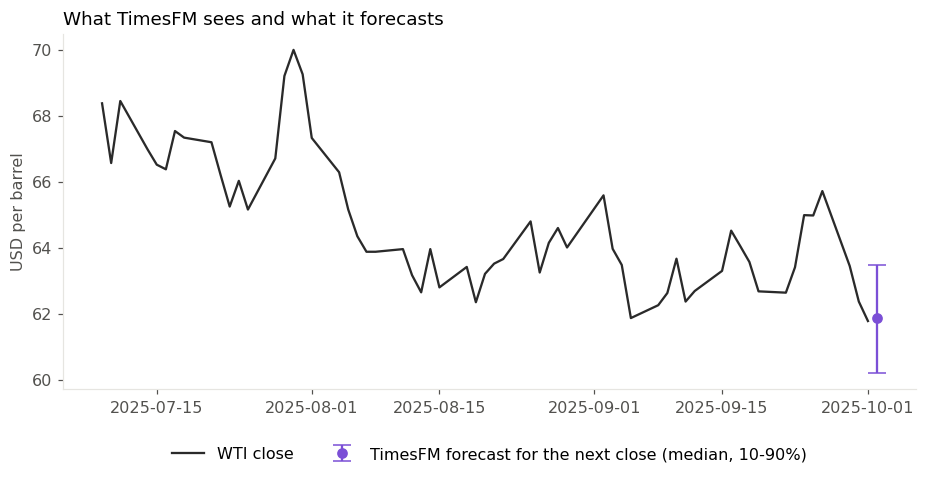

In [22]:
t = dds[0]
closes = md_.asof(t).bars["close"].to_numpy()
q = forecaster(tfm_series(closes, "price", 1024))
c = closes[-1]
move, p_up = tfm_view(q, c, "price")
band = 2 * rules.FEE_RATE
print(f"{t.date()}: close {c:.2f}")
print(f"Forecast for the next close: median {q[0.5]:.2f} ({move:+.2%}); 10% to 90% range {q[0.1]:.2f} to {q[0.9]:.2f}")
print(f"Chance of a rise read off the forecast: {p_up:.2f}")
print(f"Rule: {'LONG' if move > band else 'SHORT' if move < -band else 'FLAT'} (band ±{band:.2%})")

fig, ax = plt.subplots(figsize=(10, 4.2))
last = md_.asof(t).bars["close"].tail(60)
ax.plot(last.index, last, color="#2a2a2a", lw=1.5, label="WTI close")
ax.errorbar([md_.next_date(t)], [q[0.5]], yerr=[[q[0.5] - q[0.1]], [q[0.9] - q[0.5]]], fmt="o", color="#7b4fd6", capsize=6,
            label="TimesFM forecast for the next close (median, 10-90%)")
ax.set_ylabel("USD per barrel"); ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
ax.set_title("What TimesFM sees and what it forecasts", loc="left")
plt.show()

## 3. Choosing the input and the history, on the previous year

**The rule, fixed on 19 October 2026 before any version was scored:**
- 12 versions: TimesFM shown **prices** or **daily returns**, with **3 months, 6 months, 1, 2, 4 or 10 years** of history.
- Each forecasts the next close on every trading day from **1 October 2024 to 30 September 2025**, using only the prices up to that day.
- Each is scored on its **forecasts only, never on P&L**: the **Brier skill** of its daily chance of a rise, against always saying 50% (above zero means its chances carried information). Direction accuracy is shown alongside.
- **The best Brier skill wins, if it is above +0.01.** Otherwise no version has real forecasting skill, and Google's default (prices, 1,024 days) is kept.
- The chosen version then plays the test year **once, with no further changes**.

A caution for reading the table: with 12 versions and one year, the best may partly be luck. That is why a margin is required.

In [23]:
if SELECTION_FILE.exists():
    devf = pd.read_csv(SELECTION_FILE)
    print("forecasts read back from", SELECTION_FILE.relative_to(ROOT))
else:
    t0 = time.time()
    devf = sel.dev_forecasts(md_, forecaster, on_version=lambda kind, label: print(f"  {kind:<8} {label:<9} done, {time.time() - t0:.0f}s"))
    SELECTION_FILE.parent.mkdir(parents=True, exist_ok=True)
    devf.to_csv(SELECTION_FILE, index=False)
scores = sel.score_versions(devf)
display(scores.style.format({"brier_skill": "{:+.3f}", "brier": "{:.4f}", "direction_right": "{:.0%}", "forecasts_down": "{:.0%}",
                             "share_up_days": "{:.0%}", "median_abs_move": "{:.2%}"}))
KIND, CONTEXT, WHY = sel.choose(scores)
print(f"\nCHOSEN: {KIND}, {CONTEXT} days of history. Reason: {WHY}")

forecasts read back from data/results/timesfm_selection_dev_year.csv



CHOSEN: price, 1024 days of history. Reason: no version beat always-50% by more than +0.01 (best +0.008, price, 1 year): Google's default kept (prices, 1024 days)


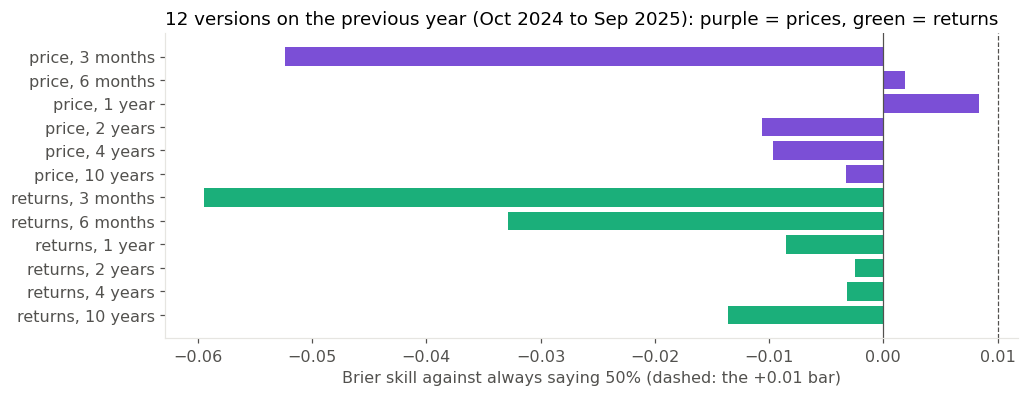

In [24]:
fig, ax = plt.subplots(figsize=(10, 3.6))
labels = [f"{k}, {h}" for k, h in scores.index]
colors = ["#7b4fd6" if k == "price" else "#1baf7a" for k, _ in scores.index]
ax.barh(labels, scores["brier_skill"], color=colors)
ax.axvline(0, color="#52514e", lw=0.8); ax.axvline(sel.MIN_SKILL, color="#52514e", lw=0.8, ls="--")
ax.invert_yaxis(); ax.set_xlabel("Brier skill against always saying 50% (dashed: the +0.01 bar)")
ax.set_title("12 versions on the previous year (Oct 2024 to Sep 2025): purple = prices, green = returns", loc="left")
plt.show()

## 4. Play the test year with the chosen version

The forecasts for the whole year are computed first, in batches (each day still sees only the prices up to that day), then the game plays day by day. One line per day: the WTI close, the position after that day's decision, the disaster stop in force, the chance of a rise, the running P&L, and the forecast behind the decision.

In [25]:
agent = TimesFMAgent(forecaster, context=CONTEXT, kind=KIND)
t0 = time.time()
agent.precompute(md_, rules.WINDOW_START, END)
print(f"{len(agent._cache)} forecasts in {time.time() - t0:.0f}s ({KIND}, {CONTEXT} days)")
view = LiveView()
res = run(md_, [agent], rules.WINDOW_START, END, on_day=view.day, on_decision=view.decision, log_dir=RESULTS / agent.name)
tfm = res[agent.name]
print(f"final P&L {tfm['balance'].iloc[-1] - 10_000:+,.0f}")

250 forecasts in 13s (price, 1024 days)
2025-10-01  WTI  61.78  timesfm_2p5    LONG   stop   57.00  p_up 0.53  P&L    -212  forecast 61.86 (+0.13%), 10-90% range 60.20-63.48; above the 0.04% ban
2025-10-02  WTI  60.48  timesfm_2p5    FLAT                 p_up 0.50  P&L    -179  forecast 60.49 (+0.01%), 10-90% range 58.63-62.28; inside the 0.04% ba
2025-10-03  WTI  60.88  timesfm_2p5    LONG   stop   56.45  p_up 0.57  P&L     -92  forecast 61.07 (+0.32%), 10-90% range 59.43-62.69; above the 0.04% ban
2025-10-06  WTI  61.69  timesfm_2p5    LONG   stop   56.45  p_up 0.51  P&L     -86  forecast 61.73 (+0.06%), 10-90% range 60.02-63.39; above the 0.04% ban
2025-10-07  WTI  61.73  timesfm_2p5    LONG   stop   56.45  p_up 0.52  P&L     +46  forecast 61.79 (+0.10%), 10-90% range 60.07-63.44; above the 0.04% ban
2025-10-08  WTI  62.55  timesfm_2p5    LONG   stop   56.45  p_up 0.59  P&L    -121  forecast 62.81 (+0.41%), 10-90% range 60.99-64.52; above the 0.04% ban
2025-10-09  WTI  61.51  timesf

## 5. What the forecasts looked like, and why it won or lost

Four checks: how big a move TimesFM expected and how often that cleared the 0.04% band; whether the direction was right; whether its forecasts lean in one direction more than oil did; and whether they follow the recent trend (momentum) or pull back towards a long-run average (mean reversion).

In [26]:
fl = pd.DataFrame(agent.log)
fl["next_close"] = tfm["log"]["next_close"].to_numpy()
fl["went_up"] = fl["next_close"] > fl["close"]
called = fl[fl["position"] != "flat"]
c_all = md_.bars["close"]
fl["ret20"] = [c_all.loc[:d].iloc[-1] / c_all.loc[:d].iloc[-21] - 1 for d in pd.to_datetime(fl["date"])]
fl["dev4y"] = [c_all.loc[:d].iloc[-1] / c_all.loc[:d].tail(1024).mean() - 1 for d in pd.to_datetime(fl["date"])]
print(f"Expected move: median {fl['expected_move'].abs().median():.2%} a day; cleared the band on {len(called)} of {len(fl)} days "
      f"({(called['position'] == 'long').sum()} long, {(called['position'] == 'short').sum()} short)")
if len(called):
    print(f"Direction of the forecast right on {((called['position'] == 'long') == called['went_up']).mean():.0%} of those days")
print(f"Forecasts pointing down: {(fl['expected_move'] < 0).mean():.0%} of days; oil actually fell on {(~fl['went_up']).mean():.0%}")
print(f"Average forecast {fl['expected_move'].mean():+.2%} a day; average actual move {(fl['next_close'] / fl['close'] - 1).mean():+.2%}")
print(f"Forecast vs the last 20 days' return: correlation {fl['expected_move'].corr(fl['ret20']):+.2f} (positive = follows the trend)")
print(f"Forecast vs distance from the 4-year average: correlation {fl['expected_move'].corr(fl['dev4y']):+.2f} (negative = pulls back to the average)")
print(f"Forecast vs the actual next-day move: correlation {fl['expected_move'].corr(fl['next_close'] / fl['close'] - 1):+.2f}")
tr = tfm["trades"]
if len(tr):
    side = tr["side"].map({1: "long", -1: "short"})
    display(tr.groupby(side).agg(trades=("pnl", "size"), pnl=("pnl", "sum"), winning=("pnl", lambda s: (s > 0).mean()))
            .style.format({"pnl": "{:+,.0f}", "winning": "{:.0%}"}))
log = tfm["log"].copy(); log["month"] = log["decision_date"].astype(str).str[:7]
display(log.groupby("month").agg(days_long=("held", lambda s: (s == "long").sum()), days_short=("held", lambda s: (s == "short").sum()),
                                 WTI=("close", "last"), balance=("balance", "last")).T.round(1))

Expected move: median 0.39% a day; cleared the band on 238 of 250 days (57 long, 181 short)
Direction of the forecast right on 46% of those days
Forecasts pointing down: 75% of days; oil actually fell on 45%
Average forecast -0.41% a day; average actual move +0.21%
Forecast vs the last 20 days' return: correlation -0.34 (positive = follows the trend)
Forecast vs distance from the 4-year average: correlation -0.58 (negative = pulls back to the average)
Forecast vs the actual next-day move: correlation -0.03


,trades,pnl,winning
side,,,
long,24,"+1,749",54%
short,28,"-5,201",43%


month,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
days_long,16.0,11.0,11.0,5.0,5.0,3.0,0.0,2.0,1.0,0.0,1.0,1.0
days_short,4.0,4.0,9.0,15.0,10.0,17.0,20.0,18.0,20.0,20.0,20.0,18.0
WTI,61.0,58.5,57.4,65.2,67.0,101.4,105.1,87.4,69.5,84.7,85.8,89.4
balance,10026.2,10435.4,10824.3,10426.2,9110.0,7044.2,6991.5,7453.3,9393.8,7690.5,7025.6,6549.0


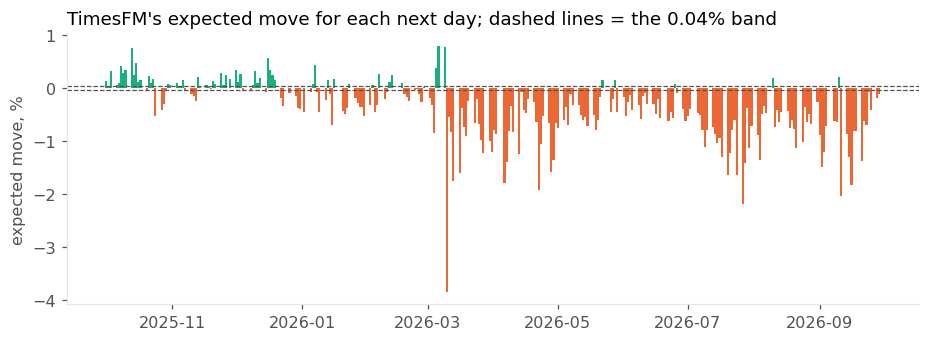

In [27]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(pd.to_datetime(fl["date"]), fl["expected_move"] * 100, color=np.where(fl["expected_move"] > 0, "#1baf7a", "#eb6834"), width=1.0)
ax.axhline(band * 100, color="#52514e", lw=0.8, ls="--"); ax.axhline(-band * 100, color="#52514e", lw=0.8, ls="--")
ax.set_ylabel("expected move, %")
ax.set_title("TimesFM's expected move for each next day; dashed lines = the 0.04% band", loc="left")
plt.show()

## 6. The simple players, the random traders, and every player played so far

Do nothing and hold oil play the same days; the 1,000 random traders are the set saved for this exact window. Every player already played in notebooks 02 and 03 is read back from `data/results/`, so the comparison includes whoever has run. Everything is written to `data/summary/` (or `data/summary_quick/`), the folder the story notebook reads.

In [28]:
base = run(md_, [Flat(), BuyAndHold()], rules.WINDOW_START, END)
null = random_traders_cached(md_, ROOT / "data" / "results", rules.WINDOW_START, END,
                             on_batch=lambda done, n, s: print(f"\r  random traders {done}/{n}  {s:.0f}s", end=""))
print("\nrandom traders for the window", null["window"].iloc[0])
everything = {**collect_saved(RESULTS), **base}
assert all(len(r["log"]) == span["days"] for r in everything.values()), "players must cover the same days (rerun any that do not)"
export_summary(everything, null, ROOT / "data" / SUMMARY_FOLDER, {**span, "quick_look": bool(QUICK), "timesfm_input": KIND,
                                                                  "timesfm_history_days": CONTEXT, "timesfm_weights": WEIGHTS,
                                                                  "run_date": str(pd.Timestamp.today().date())})
S = load_summary(ROOT, SUMMARY_FOLDER)
PLAYERS = [LABELS.get(k, k) for k in everything if k not in ("flat", "buy_and_hold")]
TSFM, BASE = ["TimesFM 2.5"], ["Do nothing (cash)", "Hold oil all year"]
print("players in this comparison:", ", ".join(PLAYERS + BASE))


random traders for the window 2025-10-01_2026-09-29_250d_n1000
players in this comparison: TimesFM 2.5, Do nothing (cash), Hold oil all year


In [29]:
scoreboard(S, TSFM + BASE)

,"P&L, USD","Return on $10,000",Beats random traders (in 100),Trades,Winning trades,Stopped out,Days long / short / flat
player,,,,,,,
TimesFM 2.5,"-3,452",-34.5%,28,52,48%,7,56 / 175 / 19
Do nothing (cash),+0,+0.0%,61,0,-,0,0 / 0 / 250
Hold oil all year,"+4,630",+46.3%,86,1,100%,0,250 / 0 / 0


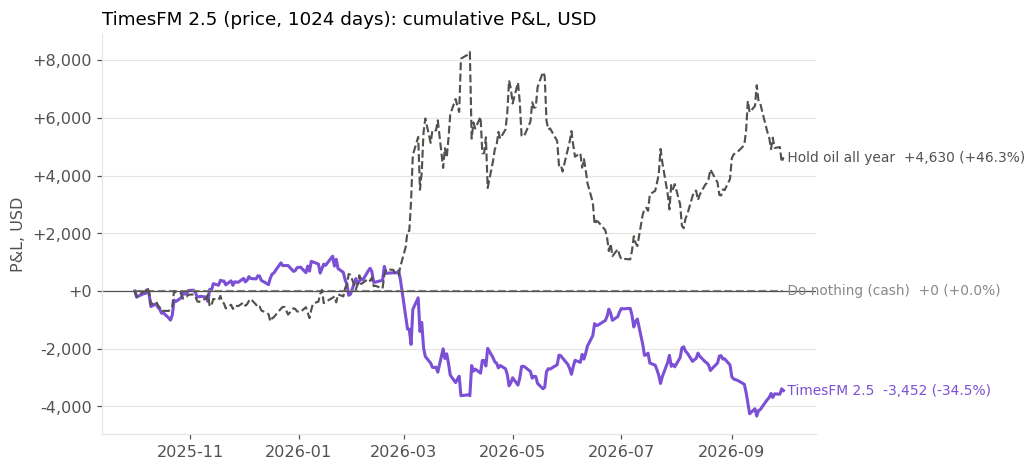

In [30]:
pnl_chart(S, TSFM + BASE, f"TimesFM 2.5 ({KIND}, {CONTEXT} days): cumulative P&L, USD");

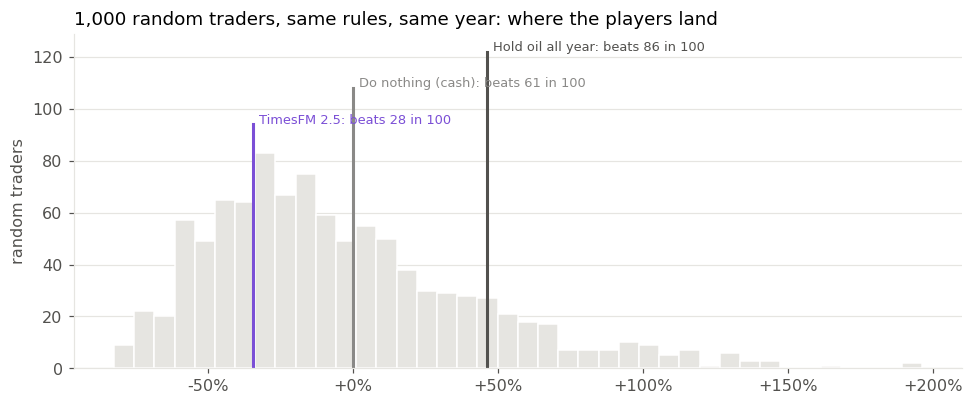

In [31]:
luck_chart(S, TSFM + BASE);

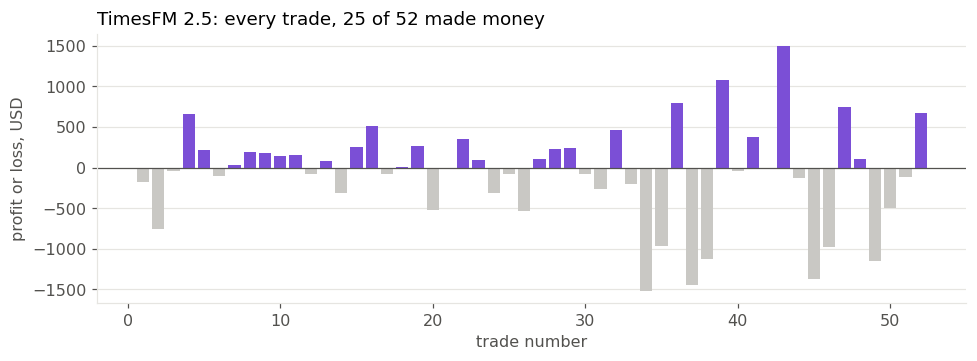

In [32]:
if not S.trades.empty and (S.trades["player"] == "TimesFM 2.5").any():
    trades_chart(S, "TimesFM 2.5"); plt.show()

### Every player so far, and did any stated chance of a rise mean anything?

A Brier score below 0.25 (always saying 50%), i.e. a skill above zero, would mean the numbers carry information.

In [33]:
scoreboard(S, PLAYERS + BASE)

,"P&L, USD","Return on $10,000",Beats random traders (in 100),Trades,Winning trades,Stopped out,Days long / short / flat
player,,,,,,,
TimesFM 2.5,"-3,452",-34.5%,28,52,48%,7,56 / 175 / 19
Do nothing (cash),+0,+0.0%,61,0,-,0,0 / 0 / 250
Hold oil all year,"+4,630",+46.3%,86,1,100%,0,250 / 0 / 0


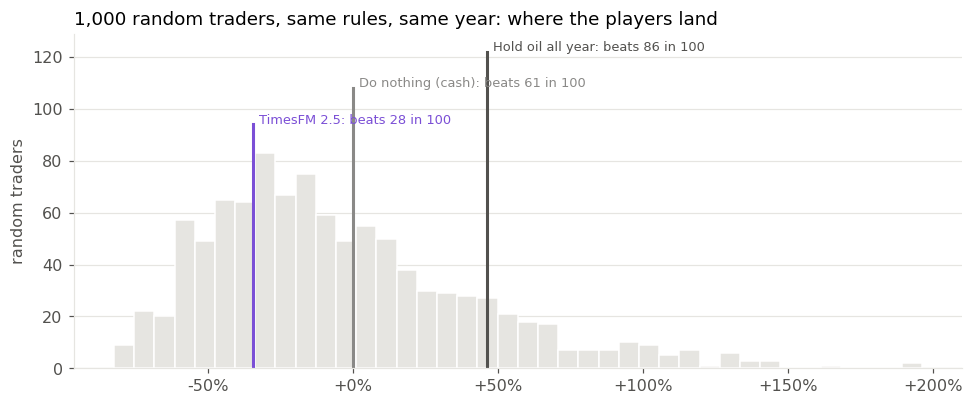

In [34]:
luck_chart(S, PLAYERS + BASE);

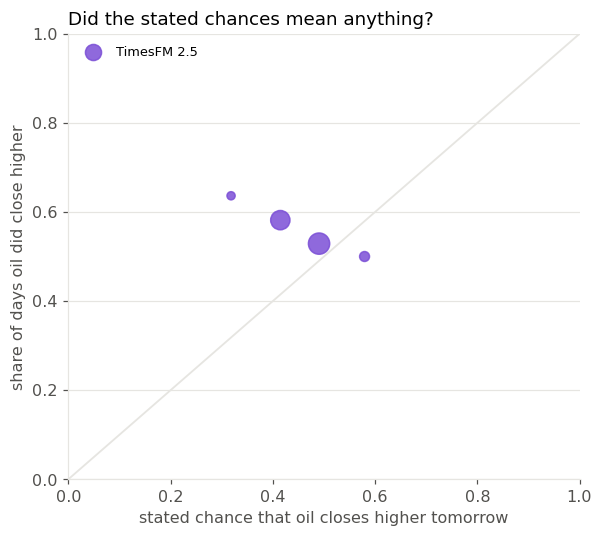

In [35]:
calibration_chart(S, PLAYERS);

In [36]:
S.players.set_index("player").loc[PLAYERS, ["n_forecasts", "n_missing", "mean_p_up", "distinct_values", "hit_rate", "share_up_days", "brier", "brier_no_view", "brier_skill"]].round(3)

,n_forecasts,n_missing,mean_p_up,distinct_values,hit_rate,share_up_days,brier,brier_no_view,brier_skill
player,,,,,,,,,
TimesFM 2.5,250,0,0.46,152,0.468,0.552,0.262,0.25,-0.047


## 6b. A check: the best of the 12 versions, played once

The rule in section 3 keeps Google's default when no version clears the +0.01 bar. A reader will ask: *did you just pick the wrong setting?* So the version with the best score on the previous year also plays the test year, **once**, as a check.

It is **not** the headline result: it did not clear the bar, and choosing it now, after seeing the scores, would be fitting the rule to the results. Whatever it makes or loses, the headline stays the version the rule chose. Its results are saved in `data/results/robustness/` and are not part of the summary the story notebook reads.

In [37]:
best = scores["brier_skill"].idxmax()
B_KIND, B_LABEL = best
B_CONTEXT = sel.CONTEXTS[B_LABEL]
print(f"Best on the previous year: {B_KIND}, {B_LABEL} ({B_CONTEXT} days), Brier skill {scores.loc[best, 'brier_skill']:+.3f} "
      f"(bar +{sel.MIN_SKILL}); headline version: {KIND}, {CONTEXT} days")
if (B_KIND, B_CONTEXT) == (KIND, CONTEXT):
    print("The best version is the headline version: nothing more to check.")
    check_res = None
else:
    check = TimesFMAgent(forecaster, context=B_CONTEXT, kind=B_KIND, name="timesfm_2p5_best_dev")
    check.precompute(md_, rules.WINDOW_START, END)
    check_res = run(md_, [check], rules.WINDOW_START, END, log_dir=RESULTS / "robustness" / check.name)[check.name]
    rows = {f"Headline: {KIND}, {CONTEXT} days": tfm, f"Check: {B_KIND}, {B_CONTEXT} days": check_res,
            "Hold oil all year": base["buy_and_hold"], "Do nothing (cash)": base["flat"]}
    table = {}
    for k, r in rows.items():
        pm, tm, fs = pnl_metrics(r["balance"]), trade_metrics(r["trades"], r["log"]), forecast_scores(r["log"])
        table[k] = {"P&L, USD": f"{r['balance'].iloc[-1] - rules.INITIAL_CAPITAL:+,.0f}",
                    "Return": f"{pm['total_return']:+.1%}",
                    "Beats random traders (in 100)": f"{beats(null['total_return'], pm['total_return']):.0f}",
                    "Trades": tm["n_trades"], "Stopped out": tm["stopped_out"],
                    "Days long / short / flat": f"{tm['days_long']} / {tm['days_short']} / {tm['days_flat']}",
                    "Brier skill (test year)": f"{fs['brier_skill']:+.3f}" if k.startswith(("Headline", "Check")) else "-"}
    display(pd.DataFrame(table).T)

Best on the previous year: price, 1 year (252 days), Brier skill +0.008 (bar +0.01); headline version: price, 1024 days


,"P&L, USD",Return,Beats random traders (in 100),Trades,Stopped out,Days long / short / flat,Brier skill (test year)
"Headline: price, 1024 days","-3,452",-34.5%,28,52,7,56 / 175 / 19,-0.047
"Check: price, 252 days","-6,134",-61.3%,5,62,10,68 / 160 / 22,-0.060
Hold oil all year,"+4,630",+46.3%,86,1,0,250 / 0 / 0,-
Do nothing (cash),+0,+0.0%,61,0,0,0 / 0 / 250,-


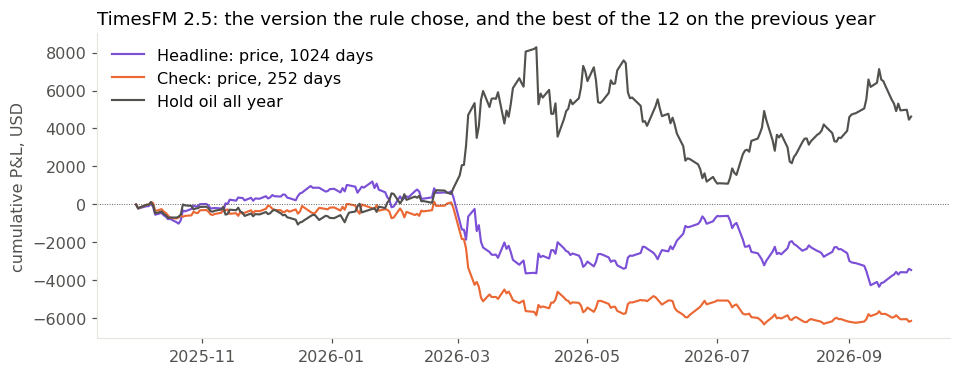

In [38]:
if check_res is not None:
    fig, ax = plt.subplots(figsize=(10, 3.6))
    for k, r, col in [(f"Headline: {KIND}, {CONTEXT} days", tfm, "#7b4fd6"), (f"Check: {B_KIND}, {B_CONTEXT} days", check_res, "#eb6834"),
                      ("Hold oil all year", base["buy_and_hold"], "#52514e")]:
        ax.plot(r["balance"].index, r["balance"] - rules.INITIAL_CAPITAL, label=k, color=col, lw=1.4)
    ax.axhline(0, color="#52514e", lw=0.6, ls=":")
    ax.set_ylabel("cumulative P&L, USD"); ax.legend(loc="upper left", frameon=False)
    ax.set_title("TimesFM 2.5: the version the rule chose, and the best of the 12 on the previous year", loc="left")
    plt.show()

## 7. What the runs found

### First run, Google's example settings (19 October 2026)

TimesFM 2.5 (weights commit `1d952420`), shown **prices with 1,024 days of history**, played the test year under the final rules:

- **−34.5%**, against **+46.3%** for holding oil and 0% for doing nothing; it beat 28 of 100 random traders.
- **Short on 175 of 250 days** in a year when oil rose 46%. Its shorts lost $5,201; its longs made $1,749 (54% of them winning). Only 7 of its 52 trades ended at the disaster stop: the stop did not decide the result.
- **Why: it forecast a return to oil's four-year average.** Its forecasts pointed down on 74% of days, while oil fell on 45%; its average forecast was −0.41% a day against an actual +0.21%. The forecasts tracked the distance from the long-run average (correlation −0.58 with the distance from the 1,024-day average, about $79) far more than the recent trend (−0.21 with the last five days). When oil was more than 10% above that average, as from March 2026, it forecast a fall on 95% of days. From October to December, with oil below $62, it was mostly long and the account rose to $10,824; from March, with oil at $85 to $105, it was short almost every day and the account fell to $6,549.
- **No forecasting skill.** The direction of its median forecast was right on 46% of the days it traded; its forecast and the next day's actual move were unrelated (correlation −0.03); its larger forecasts were less accurate than its smaller ones; and its chance of a rise scored worse than always saying 50% (Brier skill −0.047).
- **Two settings shaped this**, both taken from Google's example rather than chosen for oil: showing it price levels, which ties the forecast to the window's average level, and a four-year history, which made that average $79. Section 3 now chooses both on the previous year.

### Second run: the 12 versions, and the check

No version cleared the +0.01 bar on the previous year (best: prices, 1 year, +0.008), so the rule kept Google's default and the headline is unchanged at −34.5%. As a check, the best of the 12 also played the test year once: **−61.3%**, beating 5 of 100 random traders, short on 160 of 250 days, with a Brier skill of −0.060. Its small edge on the previous year did not carry over. Changing the setting did not fix TimesFM; it forecast a return to the average whatever history it was shown, in a year when oil kept rising.